# P1-01. 데이터 탐색 (Brain MRI 분류 프로젝트)

**이 노트북의 목표**
1. GPU 환경 확인
2. `data/raw` 안에 있는 압축 파일 자동 해제
3. 데이터셋 전체 구조 파악 (어떤 폴더에 이미지가 몇 장 있는지)
4. 뇌종양 MRI 데이터 찾기 → 클래스별 개수, 이미지 크기·채널 확인, 샘플 보기
5. **중복 이미지 검사** — 완전히 같은 파일(MD5) + 거의 같은 이미지(aHash)

> 모든 셀을 위에서부터 순서대로 실행하세요 (`Run All`도 OK).  
> 실행이 끝나면 **3번, 4번, 5번 셀 출력**을 복사해서 Claude에게 붙여주세요.

## 0. 환경 확인

In [19]:
import torch, sys, platform
print("Python :", sys.version.split()[0], "|", platform.system())
print("torch  :", torch.__version__, "| CUDA 사용 가능:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    p = torch.cuda.get_device_properties(i)
    print(f"  GPU {i}: {p.name}, {p.total_memory/1024**3:.1f} GB")

Python : 3.12.0 | Windows
torch  : 2.11.0+cu128 | CUDA 사용 가능: True
  GPU 0: NVIDIA GeForce RTX 3080, 10.0 GB
  GPU 1: NVIDIA GeForce RTX 3080, 10.0 GB


## 1. 경로 설정

이 노트북은 `medimg-study/01_classification_brain_mri/notebooks/` 안에 있다고 가정해요.  
그래서 데이터 폴더는 두 단계 위의 `data/raw`예요. 위치가 다르면 `DATA_ROOT`만 고쳐주세요.

In [20]:
from pathlib import Path

DATA_ROOT = Path("../../data/raw").resolve()
print("DATA_ROOT:", DATA_ROOT)
print("존재 여부:", DATA_ROOT.exists())
assert DATA_ROOT.exists(), "data/raw 폴더를 찾을 수 없어요. 경로를 확인해 주세요."

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".dcm"}

DATA_ROOT: D:\yerimlee\medimg-study\data\raw
존재 여부: True


## 2. 압축 파일 자동 해제

Mendeley에서 받으면 압축 안에 압축이 또 들어있는 경우가 많아요.  
`data/raw` 안의 `.zip`을 찾아서 **같은 이름의 폴더**에 풀어요. 이미 풀린 건 건너뛰어요. (안쪽 압축이 또 나오면 반복)

In [21]:
import zipfile

def extract_all_zips(root: Path, max_rounds: int = 5):
    for rnd in range(max_rounds):
        zips = [z for z in root.rglob("*.zip") if not z.with_suffix("").exists()]
        if not zips:
            break
        for z in zips:
            target = z.with_suffix("")
            print(f"[{rnd+1}회차] 압축 해제: {z.relative_to(root)}")
            with zipfile.ZipFile(z) as zf:
                for m in zf.infolist():          # 압축 밖으로 파일이 나가는 경로 차단
                    dest = (target / m.filename).resolve()
                    if not str(dest).startswith(str(target.resolve())):
                        raise ValueError(f"의심스러운 경로: {m.filename}")
                zf.extractall(target)
    print("압축 해제 완료")

extract_all_zips(DATA_ROOT)

압축 해제 완료


## 3. 전체 구조 파악

이미지 파일이 **직접 들어있는 폴더**만 골라서, 경로와 장수를 보여줘요.  
보통 `데이터셋/(train|test)/클래스명/이미지` 형태예요. → **이 출력을 Claude에게 보내주세요.**

In [22]:
import pandas as pd
from collections import Counter

files = [p for p in DATA_ROOT.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT]
print(f"전체 이미지 파일: {len(files):,}장")
print("확장자 분포:", dict(Counter(p.suffix.lower() for p in files)))

folder_counts = Counter(p.parent for p in files)
struct = (pd.DataFrame([(str(f.relative_to(DATA_ROOT)), n) for f, n in folder_counts.items()],
                       columns=["folder", "n_images"])
            .sort_values("folder").reset_index(drop=True))
pd.set_option("display.max_rows", 200, "display.max_colwidth", 120)
struct

전체 이미지 파일: 24,880장
확장자 분포: {'.jpg': 23892, '.png': 988}


,folder,n_images
0,Medical Imagining\Bone Break Classification\Avulsion fracture\Test,14
1,Medical Imagining\Bone Break Classification\Avulsion fracture\Train,109
2,Medical Imagining\Bone Break Classification\Comminuted fracture\Test,14
3,Medical Imagining\Bone Break Classification\Comminuted fracture\Train,134
4,Medical Imagining\Bone Break Classification\Fracture Dislocation\Test,19
5,Medical Imagining\Bone Break Classification\Fracture Dislocation\Train,137
6,Medical Imagining\Bone Break Classification\Greenstick fracture\Test,16
7,Medical Imagining\Bone Break Classification\Greenstick fracture\Train,106
8,Medical Imagining\Bone Break Classification\Hairline Fracture\Test,10
9,Medical Imagining\Bone Break Classification\Hairline Fracture\Train,101


## 4. 뇌종양 MRI 데이터 찾기

폴더 경로에 `brain`이 들어간 이미지들을 모아요.  
클래스 이름 = 이미지가 들어있는 **바로 위 폴더 이름**,  
split(train/test) = 경로 중에 train/test/val 같은 단어가 있으면 그걸로 표시해요.

> 만약 `brain`으로 아무것도 안 잡히면, 3번 표를 보고 `KEYWORD`를 바꿔주세요 (예: `"mri"`, `"tumor"`).

In [23]:
import re

KEYWORD = "brain"

def split_of(p: Path) -> str:
    for part in p.relative_to(DATA_ROOT).parts[:-1]:
        s = part.lower()
        if re.search(r"train", s): return "train"
        if re.search(r"test", s):  return "test"
        if re.search(r"val", s):   return "val"
    return "(구분없음)"

brain = [p for p in files if KEYWORD in str(p.relative_to(DATA_ROOT)).lower()]
df = pd.DataFrame({
    "path":  brain,
    "label": [p.parent.name for p in brain],
    "split": [split_of(p) for p in brain],
})
print(f"'{KEYWORD}' 이미지: {len(df):,}장")
pd.crosstab(df["label"], df["split"], margins=True, margins_name="합계")

'brain' 이미지: 7,023장


split,test,train,합계
label,,,
glioma,300,1321,1621
meningioma,306,1339,1645
notumor,405,1595,2000
pituitary,300,1457,1757
합계,1311,5712,7023


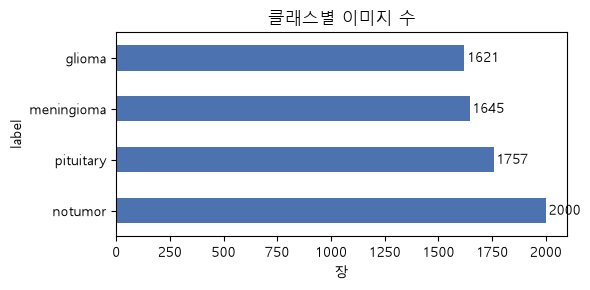

In [24]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
_avail = {f.name for f in font_manager.fontManager.ttflist}
for _f in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:   # 한글 폰트 (Windows는 맑은 고딕)
    if _f in _avail:
        plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

ax = df["label"].value_counts().plot(kind="barh", figsize=(6, 3), color="#4C72B0")
ax.set_title("클래스별 이미지 수"); ax.set_xlabel("장")
for c in ax.containers: ax.bar_label(c, padding=2)
plt.tight_layout(); plt.show()

### 4-1. 이미지 속성 (크기·채널)

딥러닝 모델은 **입력 크기가 모두 같아야** 해요. 그래서 원본 크기가 얼마나 제각각인지,  
흑백(`L`)인지 컬러(`RGB`)인지 확인해요. 전체를 다 열면 느리니 클래스별 최대 200장씩 샘플링해요.
흑백과 컬러의 채널의 수가 달라서 행렬 (텐서)의 모양 자체가 달라지는 문제가 있어서 확인하는 과정.
흑백의 경우 H*W이지만, 컬러의 경우 H*W*3 (RGB채널 3개)로 배열모양이 나타나기 때문임.

In [25]:
from PIL import Image

sample = pd.concat([g.sample(min(len(g), 200), random_state=0) for _, g in df.groupby("label")]).copy()
props = []
for p in sample["path"]:
    with Image.open(p) as im:
        props.append((im.size[0], im.size[1], im.mode))
sample["width"]  = [w for w, h, m in props]
sample["height"] = [h for w, h, m in props]
sample["mode"]   = [m for w, h, m in props]

print("채널(mode) 분포:", sample["mode"].value_counts().to_dict())
print("\n가로·세로 크기 요약:")
print(sample[["width", "height"]].describe().round(0).astype(int).T)
print("\n가장 흔한 크기 Top 5:")
print((sample["width"].astype(str) + "x" + sample["height"].astype(str)).value_counts().head())

채널(mode) 분포: {'RGB': 423, 'L': 377}

가로·세로 크기 요약:
        count  mean  std  min  25%  50%  75%   max
width     800   449  125  150  442  512  512  1149
height    800   452  120  168  442  512  512  1019

가장 흔한 크기 Top 5:
512x512    564
225x225     37
630x630      9
206x244      8
228x221      8
Name: count, dtype: int64


In [26]:
# Claude) MRI는 흑백영상인데 RGB가 나온 이유는 R=G=B인 컬러형식으로 저장된 흑백 이미지인 가능성이 있어서 진짜 색 정보가 있는 파일인지는 아래 코드를 통해 확인하였음 
rgb_paths = sample[sample["mode"] == "RGB"]["path"]
is_gray = []
for p in rgb_paths:
    a = np.asarray(Image.open(p))
    is_gray.append(np.array_equal(a[..., 0], a[..., 1]) and np.array_equal(a[..., 1], a[..., 2]))
print(f"RGB 이미지 {len(is_gray)}장 중 실제로는 흑백(R=G=B): {sum(is_gray)}장")

RGB 이미지 423장 중 실제로는 흑백(R=G=B): 409장


 max_diff  colored_pixel_%
       47             2.04
       30             1.81
       14             2.85
       14             0.12
        9             0.00
        8             0.00
        8             0.00
        6             0.00
        6             0.00
        5             0.00
        5             0.00
        5             0.00
        4             0.00
        2             0.00


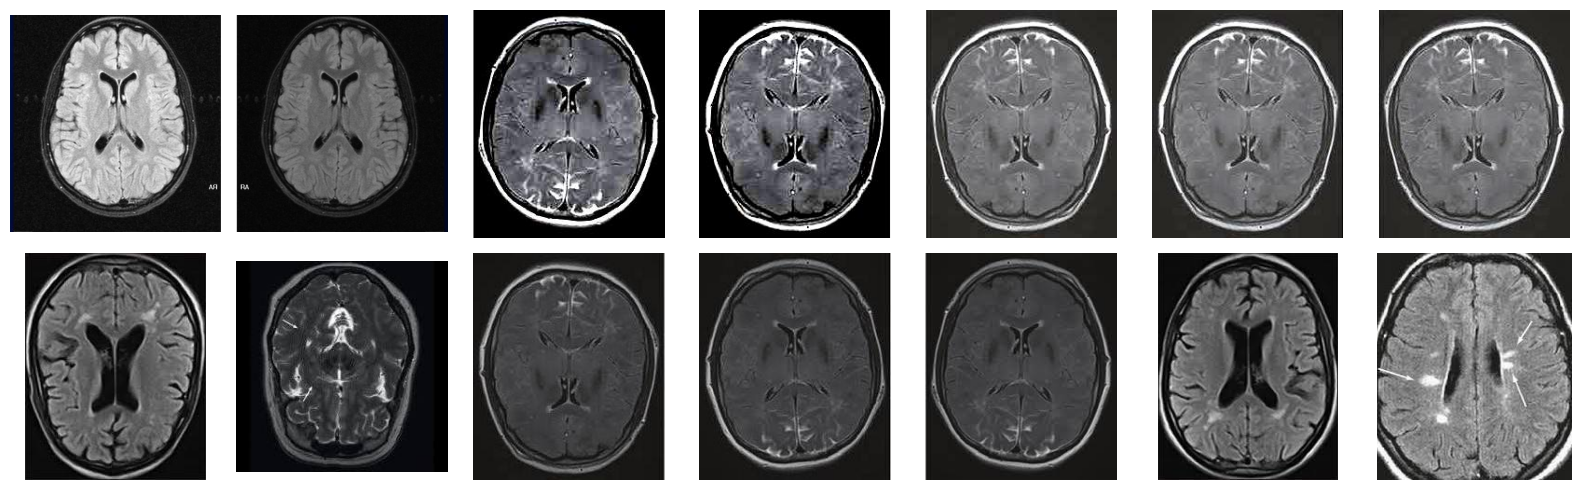

In [27]:
# 423장 중 409장은 R=G=B인 이미지로 나머지 14장에 대한 확인이 필요 
# 1) 진짜 색이 들어간 이미지인지 (화살표 혹은 표시선과 같은 컬러주석 혹은 컬러맵이 올라간 영상이 섞인 경우)
# 2) JPEG 압축으로 인해 생긴 오차 
rgb_paths = sample[sample["mode"] == "RGB"]["path"].tolist()

rows = []
for p in rgb_paths:
    a = np.asarray(Image.open(p)).astype(int)
    diff = np.max([np.abs(a[..., 0] - a[..., 1]), np.abs(a[..., 1] - a[..., 2])], axis=0)
    if diff.max() > 0:
        rows.append({"path": p, "max_diff": diff.max(),
                     "colored_pixel_%": (diff > 10).mean() * 100})   # 10 넘게 차이나는 픽셀 비율

nongray = pd.DataFrame(rows).sort_values("max_diff", ascending=False)
print(nongray[["max_diff", "colored_pixel_%"]].round(2).to_string(index=False))

# 이미지 직접 보기
fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for ax, p in zip(axes.ravel(), nongray["path"]):
    ax.imshow(Image.open(p)); ax.axis("off")
for ax in axes.ravel()[len(nongray):]: ax.axis("off")
plt.tight_layout(); plt.show()

In [28]:
# 확인 결과: amx_diff가 작고 colored pixel 이 거의 0%에 가까우며, 육안으로 확인했을 때도 컬러는 찾아볼 수 없어서 모두 흑백 이미지로 간주함 
# 모든 이미지를 3채널로 통일함 (사용하려고 하는 pretrained model의 대부분이 컬러 이미지 (RGB 3채널)로 학습되어 있으며, 흑백 이미지로 학습된 모델도 있기는 하나 입력은 3채널 형식인 모델이 꽤 많은편)

### 4-2. 클래스별 샘플 이미지

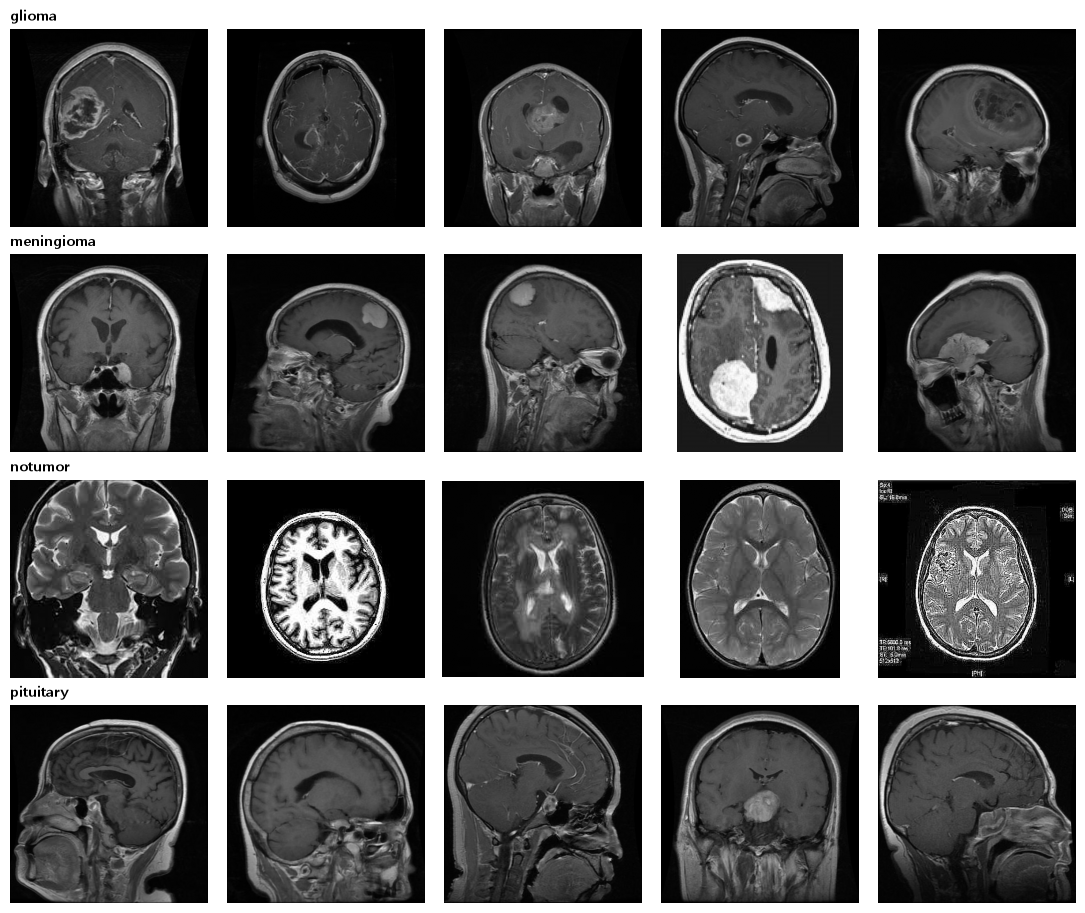

In [29]:
# 확인할 내용: 1) 각 클래스별로 특정 단면만 있지는 않은지? 2) 특정 클래스의 이미지가 유독 밝거나 어둡지는 않은지? 3) 검은 여백이 다른 클래스보다 많거나 적은지, 사진의 크기가 얼마나 큰지
# 확인할 내용: 4) 화살표, 글자, 워터마크, 눈금자 등의 표시가 있는지? 5) 뇌가 아닌 사진, 거꾸로 된 사진, 거의 까만 사진이 있는지? 
N = 5
labels = sorted(df["label"].unique())
fig, axes = plt.subplots(len(labels), N, figsize=(N * 2.2, len(labels) * 2.3))
axes = axes.reshape(len(labels), N)
for r, lab in enumerate(labels):
    paths = df[df["label"] == lab]["path"].sample(min(N, (df["label"] == lab).sum()), random_state=1)
    for c, ax in enumerate(axes[r]):
        ax.axis("off")
        if c < len(paths):
            ax.imshow(Image.open(paths.iloc[c]).convert("L"), cmap="gray")
        if c == 0:
            ax.set_title(lab, loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()

In [30]:
# 단면방향: notumor(정상)은 대부분 위에서 찍은 사지닝 많은거 같아. pituitary는 위에서 찍은 사진이 하나도 없어. glioma, meningioma 두개는 단면 방향별 개수 분포가 거의 동일한거 같아. 좀 고르게 데이터를 가지고 있는 느낌?
# 밝기대비스타일: 대부분 큰 차이 없는데 notumor에서는 유난히 밝은 이미지가 2개 정도 있는거 같아
# 테두리여백크기: pituitary 이미지;가 glioma, meningioma 보다 이미지가 조금 큰거 같아 특히 양옆단면이미지
# 글자표시: 이거는 notumor 마지막 이미지에 좀 있는거 같아
# 명백한이상: 이건 없는거 같아.

# 관찰 피드백

# 단면 방향: 정확해요.
# pituitary는 옆면(sagittal)과 정면(coronal)뿐인데, 이건 의학적으로도 자연스러워요. 뇌하수체는 뇌 한가운데 아래쪽에 있어서 그 방향으로 찍어야 잘 보이거든요. 5장 중 4번째 정면 사진에서 가운데 아래 하얀 덩어리가 보이죠? 그게 뇌하수체 종양이에요.
# notumor는 위에서 본 단면(axial)이 대부분이에요.
# 그러면 모델은 "옆면이면 pituitary, 위에서 본 거면 notumor"라는 지름길을 배울 수 있어요. 병변을 안 보고도 꽤 맞힐 수 있다는 뜻이에요.

# 밝기·대비: 여기에 제일 큰 단서가 있어요. 2장만 튀는 게 아니라, notumor 전체가 다른 촬영 방식처럼 보여요.
# glioma, meningioma, pituitary 사진을 보면 뇌 가운데 나비 모양 공간(뇌실, 뇌척수액이 차 있는 곳)이 까맣게 나와요. 이건 T1 강조영상, 특히 조영제를 쓴 영상의 특징이에요.
# notumor는 1, 3, 4, 5번째 사진에서 뇌실이 하얗게 나와요. 이건 T2 강조영상의 특징이에요.
# 즉 **”뇌실이 하얗다 → notumor”**라는, 병변과 전혀 상관없는 단서가 있을 가능성이 커요. 아까 말한 “notumor가 다른 출처에서 왔다”는 지적이 이거예요.

# 테두리·크기: 좋은 발견이에요. pituitary는 머리가 화면을 꽉 채우게 확대되거나 잘린 느낌이에요. 이것도 출처나 촬영 프로토콜 차이일 수 있어요.

# 글자·표시: 맞아요. notumor 마지막 사진의 왼쪽 위와 오른쪽 아래에 촬영 정보 글자가 있어요. 장비 화면을 그대로 캡처한 이미지예요.

# 명백한 이상: 이 5장에서는 없어요.

# --> 위의 이미지 별 차이점에 의해서 학습될 편향이 있어서 해당 부분을 방지하기 위해서 아래 2개의 단계를 추가하기로 하였음. 
# 5단계 Grad-CAM: notumor를 맞힐 때 모델이 뇌실 밝기나 글자를 보는지, pituitary를 맞힐 때 뇌하수체 위치를 보는지 확인해요.
# "저해상도 지름길 테스트": 이미지를 16×16으로 뭉개서 병변이 보이지 않게 만든 다음, 로지스틱 회귀나 랜덤포레스트로 분류해봐요. 이 상태에서도 정확도가 높게 나오면, 병변이 아니라 전체적인 생김새(방향, 밝기)로 구분이 된다는 증거예요.

## 5. 중복 이미지 검사 ⭐

의료영상 공개 데이터에서 **가장 흔한 함정**이에요. 같은 이미지가 train과 test에 동시에 있으면,  
모델이 "외운 걸 맞히는" 상황이 돼서 성능이 부풀려져요.

- **MD5**: 파일 내용이 바이트 단위로 완전히 같은 경우
- **aHash**: 이미지를 8×8로 줄여 밝기 패턴만 비교 → 저장 형식·크기만 다른 *거의 같은* 이미지까지 잡아요

In [31]:
import hashlib
import numpy as np
from tqdm.auto import tqdm

def md5(p):
    return hashlib.md5(p.read_bytes()).hexdigest()

def ahash(p, size=8):
    with Image.open(p) as im:
        a = np.asarray(im.convert("L").resize((size, size), Image.BILINEAR), dtype=np.float32)
    return "".join("1" if v else "0" for v in (a > a.mean()).ravel())

# MD5: 파일을 바이트 단위로 읽어서 비교 (1바이트만 달라도 완전히 다른값이 나옴)하며, MD5가 같으면 완전히 동일한 파일임 - 신뢰가능
df["md5"]   = [md5(p)   for p in tqdm(df["path"], desc="MD5")]

# 실제 데이터는 512*512
# aHash: 이미지를 8*8로 줄인 파일로 비교하는 방식으로 겉모습이 비슷하면 같은 코드가 나옴 (사진을 뭉개서 확인하는거랑 비슷함. 디테일이 달라도 뭉개면 비슷해지기 때문에 대충 봤을때 비슷한 사진이면 걸림) - 과대검출
# MRI는 까만배경 + 가운데 둥근 뇌라는 구도가 거의 같아서 8*8에서는 많은 사진들이 비슷해보일수있음 
df["ahash"] = [ahash(p) for p in tqdm(df["path"], desc="aHash")]

def dup_report(key, name):
    g = df.groupby(key)
    dup_groups = g.filter(lambda x: len(x) > 1)
    n_groups = dup_groups[key].nunique()
    extra = len(dup_groups) - n_groups
    cross_split = g.filter(lambda x: x["split"].nunique() > 1)[key].nunique()
    cross_label = g.filter(lambda x: x["label"].nunique() > 1)[key].nunique()
    print(f"[{name}] 중복 그룹 {n_groups:,}개 | 지워도 되는 여분 {extra:,}장 ({extra/len(df):.1%})")
    print(f"   └ train/test에 걸친 그룹: {cross_split:,}개  ← 누수(leakage) 위험")
    print(f"   └ 서로 다른 클래스에 걸친 그룹: {cross_label:,}개  ← 라벨 오류 가능성")
    return dup_groups

dup_md5 = dup_report("md5", "완전 중복(MD5)")
dup_ah  = dup_report("ahash", "유사 중복(aHash)")

aHash: 100%|██████████| 7023/7023 [00:12<00:00, 563.93it/s]


[완전 중복(MD5)] 중복 그룹 194개 | 지워도 되는 여분 297장 (4.2%)
   └ train/test에 걸친 그룹: 79개  ← 누수(leakage) 위험
   └ 서로 다른 클래스에 걸친 그룹: 0개  ← 라벨 오류 가능성
[유사 중복(aHash)] 중복 그룹 981개 | 지워도 되는 여분 3,865장 (55.0%)
   └ train/test에 걸친 그룹: 525개  ← 누수(leakage) 위험
   └ 서로 다른 클래스에 걸친 그룹: 277개  ← 라벨 오류 가능성


**각 숫자의 의미 (MD5 결과 기준)**

| 항목 | 값 | 의미 |
|---|---|---|
| 중복 그룹 | 194개 | 2장 이상 존재하는 **사진 종류**의 수 (train/test 불문) |
| 지워도 되는 여분 | 297장 (4.2%) | 종류마다 1장만 남기면 지울 수 있는 **복사본 수** (관련 이미지 총 491장 = 194 + 297) |
| train/test에 걸친 그룹 | 79개 | 194종류 중 train·test **양쪽에** 들어간 종류 수 → **누수** (장수는 79보다 많을 수 있음) |
| 서로 다른 클래스 그룹 | 0개 | 같은 사진에 다른 라벨이 붙은 경우 없음 ✅ |

**예시**: 사진1이 train에 2장, test에 1장 있을 때
- 중복 그룹 **1개**, train/test에 걸친 그룹 **1개**, 지워도 되는 여분 **2장**
- 처리: train 1장 남김 → train 나머지 1장 삭제(같은 split 내 여분) + test 1장 삭제(누수 제거)
- 이 여분을 194개 그룹에 대해 모두 더한 값 = 297장

**처리 원칙**
- 같은 사진은 반드시 **한쪽 split에만** 존재해야 함
- train에 짝이 있는 test 이미지는 **test에서 제거** (test = 처음 보는 문제여야 하므로)
- 같은 split 안의 중복은 **1장만** 남김

In [32]:
# 엄격한 유사 중복 검사: 16x16 해시로 후보 → 64x64 픽셀 비교로 확정
def thumb(p, size=64):
    with Image.open(p) as im:
        return np.asarray(im.convert("L").resize((size, size), Image.BILINEAR), dtype=np.float32)

df["ahash16"] = [ahash(p, size=16) for p in tqdm(df["path"], desc="aHash16")]

THRESH = 5.0   # 64x64 평균 픽셀 차이(0~255)가 이보다 작으면 같은 이미지로 판단
pairs = []
for h, g in df.groupby("ahash16"):
    if len(g) < 2: continue
    idx = g.index.tolist()
    th = {i: thumb(df.at[i, "path"]) for i in idx}
    for a in range(len(idx)):
        for b in range(a + 1, len(idx)):
            i, j = idx[a], idx[b]
            d = np.abs(th[i] - th[j]).mean()
            if d < THRESH:
                pairs.append((i, j, d))

pairs = pd.DataFrame(pairs, columns=["i", "j", "pix_diff"])
pairs["cross_split"] = df.loc[pairs["i"], "split"].values != df.loc[pairs["j"], "split"].values
pairs["cross_label"] = df.loc[pairs["i"], "label"].values != df.loc[pairs["j"], "label"].values
print(f"유사 중복 쌍: {len(pairs):,}개")
print(f"  └ train/test에 걸친 쌍: {pairs['cross_split'].sum():,}개")
print(f"  └ 서로 다른 클래스 쌍: {pairs['cross_label'].sum():,}개")

# 다른 클래스로 묶인 쌍이 있으면 눈으로 확인
show = pairs[pairs["cross_label"]].head(5)
if len(show):
    fig, axes = plt.subplots(len(show), 2, figsize=(5, 2.5 * len(show)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(show.iterrows()):
        for c, k in enumerate(["i", "j"]):
            rr = df.loc[row[k]]
            axes[r, c].imshow(Image.open(rr["path"]).convert("L"), cmap="gray")
            axes[r, c].set_title(f"{rr['split']}/{rr['label']} (차이 {row['pix_diff']:.1f})", fontsize=8)
            axes[r, c].axis("off")
    plt.tight_layout(); plt.show()

aHash16: 100%|██████████| 7023/7023 [00:12<00:00, 541.75it/s]


유사 중복 쌍: 1,981개
  └ train/test에 걸친 쌍: 763개
  └ 서로 다른 클래스 쌍: 0개


### 📝 메모: 쌍(pair) → 묶음(group)으로 합치는 이유

**16×16 + 픽셀 비교 결과는 "쌍" 단위**
- 유사 중복 쌍 1,981개 / train·test에 걸친 쌍 763개 / 다른 클래스 쌍 0개
- ⚠️ 쌍 수 ≠ 이미지 수. 같은 사진이 여러 장이면 쌍이 여러 번 카운트됨

**예시**: 사진1이 train에 2장(A, B), test에 1장(C) 있을 때

| 쌍 | split | 카운트 |
|---|---|---|
| A – B | train – train | 유사 중복 쌍 1 |
| A – C | train – **test** | 유사 중복 쌍 1, **train/test 쌍 1** |
| B – C | train – **test** | 유사 중복 쌍 1, **train/test 쌍 1** |

→ 쌍으로 세면 **유사 중복 3쌍, train/test 2쌍**
→ 실제로는 **사진 1종류, 3장, 누수 test 이미지는 C 1장뿐**

**묶음 코드(Union-Find)가 하는 일**: 연결된 쌍을 하나의 묶음으로 합침

    쌍:   A-B, A-C, B-C   →   묶음: {A, B, C}

- 중복 묶음 1개 / 중복에 얽힌 이미지 3장 / 지워도 되는 여분 2장 / 누수 test 이미지 1장(C)

**묶음이 필요한 또 하나의 이유**: 쌍을 일부 놓쳐도 연결됨 ("친구의 친구는 같은 무리")

    쌍:   A-B, B-C (A-C는 기준 근처라 못 잡음)   →   묶음: {A, B, C}

**정리**

| | 16×16 결과 | 묶음 코드 결과 |
|---|---|---|
| 세는 단위 | 같은 사진끼리의 **쌍** | **사진 종류 / 장수** |
| 같은 사진 3장이면 | 3쌍 | 1묶음, 3장 |
| 누수 | train/test 쌍 763개 | 누수 test 이미지 ○장 ← **실제로 지울 장수** |

→ 최종 숫자는 **묶음 코드 결과**를 사용

**처리 후 저장 파일** (`outputs/p1/`)
- `brain_index.csv`: 원본 7,023장 전체 + 묶음 번호(`dup_group`) + 누수 표시(`test_leak`)
- `brain_index_clean.csv`: 누수 test 제거 + split 내 중복 1장만 남긴 깨끗한 버전
- 두 파일을 다 남기는 이유: 다음 노트북에서 **원본 test vs 깨끗한 test 성능 비교** (누수가 성능을 얼마나 부풀리는지 확인)

중복에 얽힌 이미지: 1,648장 / 7,023장 (23.5%)
중복 묶음 수: 605개
train에 짝이 있는 test 이미지: 413장 / test 1,311장 (31.5%)

클래스별 누수 test 이미지 수:
label
notumor       295
meningioma    108
pituitary       6
glioma          4
Name: count, dtype: int64


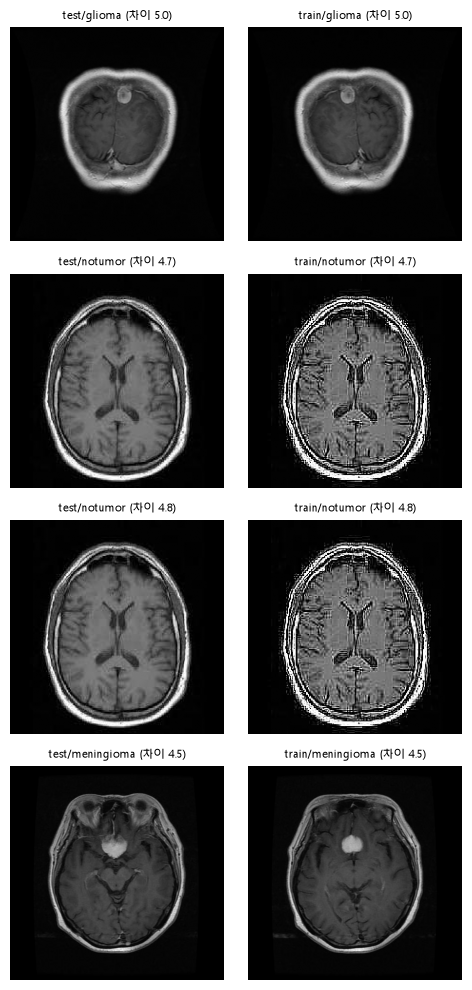


원본 7,023장 → 깨끗한 버전 5,980장
split       test  train    합계
label                        
glioma       295   1303  1598
meningioma   196   1327  1523
notumor       97   1025  1122
pituitary    294   1443  1737
합계           882   5098  5980
저장: D:\yerimlee\medimg-study\outputs\p1\brain_index.csv (7,023행)
저장: D:\yerimlee\medimg-study\outputs\p1\brain_index_clean.csv (5,980행)


In [33]:
# 위의 16*16에서 서로다른 클래스가 0건이 나왔으니 16*16을 기준으로 쌍으로 만드는 과정 진행
# 16*16, 64*64 등 다양한 옵션이 있지만 16*16 으로 진행한 이유는 연산량과도 연관이 있음 
# 우선 16*16으로 진행한 후 괜찮은지도 결과를 통해 검증하였음 

# 1) 쌍 → 묶음(그룹)으로 합치기 (Union-Find)
parent = {i: i for i in df.index}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x
for i, j in zip(pairs["i"], pairs["j"]):
    parent[find(i)] = find(j)

df["dup_group"] = [find(i) for i in df.index]
gsize = df["dup_group"].map(df["dup_group"].value_counts())
in_dup = df[gsize > 1]
print(f"중복에 얽힌 이미지: {len(in_dup):,}장 / {len(df):,}장 ({len(in_dup)/len(df):.1%})")
print(f"중복 묶음 수: {in_dup['dup_group'].nunique():,}개")

train_groups = set(df.loc[df["split"] == "train", "dup_group"])
df["test_leak"] = (df["split"] == "test") & df["dup_group"].isin(train_groups) & (gsize > 1)
print(f"train에 짝이 있는 test 이미지: {df['test_leak'].sum():,}장 / test {(df['split']=='test').sum():,}장 "
      f"({df['test_leak'].sum()/(df['split']=='test').sum():.1%})")
print("\n클래스별 누수 test 이미지 수:")
print(df[df["test_leak"]]["label"].value_counts())

# 2) 기준 경계(차이 3~5)에 걸린 train/test 쌍 눈으로 확인
edge = pairs[(pairs["cross_split"]) & (pairs["pix_diff"] > 3)].head(4)
if len(edge):
    fig, axes = plt.subplots(len(edge), 2, figsize=(5, 2.5 * len(edge)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(edge.iterrows()):
        for c, k in enumerate(["i", "j"]):
            rr = df.loc[row[k]]
            axes[r, c].imshow(Image.open(rr["path"]).convert("L"), cmap="gray")
            axes[r, c].set_title(f"{rr['split']}/{rr['label']} (차이 {row['pix_diff']:.1f})", fontsize=8)
            axes[r, c].axis("off")
    plt.tight_layout(); plt.show()

# 3) 깨끗한 버전: test 누수 제거 + split 내 중복은 1장만
clean = df[~df["test_leak"]].drop_duplicates(subset=["split", "dup_group"], keep="first")
print(f"\n원본 {len(df):,}장 → 깨끗한 버전 {len(clean):,}장")
print(pd.crosstab(clean["label"], clean["split"], margins=True, margins_name="합계"))

# 4) 저장
out = Path("../../outputs/p1").resolve(); out.mkdir(parents=True, exist_ok=True)
for name, d in [("brain_index.csv", df), ("brain_index_clean.csv", clean)]:
    s = d.drop(columns=["md5", "ahash", "ahash16"], errors="ignore").copy()
    s["path"] = s["path"].map(lambda p: str(Path(p).relative_to(DATA_ROOT)))
    s.to_csv(out / name, index=False, encoding="utf-8-sig")
    print("저장:", out / name, f"({len(s):,}행)")

# 중복 이미지 개수가 1648개이며, 중복 이미지 종류는 605개임
# 1648장 중에서 605장을 제외한 1043장은 지워도 되며 (중복이니까), train과 test 모두 있는 사진은 전체 테스트 이미지인 1311장 중에서 413장 (31%)이며, 중복 이미지의 개수가 413장

#notumor (선명도만 다름): 정확해요. 같은 사진에 샤프닝 처리만 한 거예요. 명백한 같은 사진이에요.
# glioma (좌우 반전): 반전이든 아니든 같은 사진의 변형이라 누수로 보는 게 맞아요. 데이터를 늘리려고 반전 사본을 넣는 경우가 있는데, 그게 test에 들어가면 똑같이 문제예요.
# meningioma (같은 사람을 비슷한 시간에 구도만 다르게): 아주 중요한 관찰이에요. 이건 같은 사진이 아니라 같은 환자의 다른 촬영이나 인접 단면일 가능성이 있어요.
# --> 동일한 환자의 사진은 train과 test에 나뉘어 들어가면 안됨 (환자단위분할)

### 📝 메모: 중복 정리 결과
- 원본 7,023장 → 깨끗한 버전 **5,980장** (−1,043장)
- 누수 test 413장: notumor 295 / meningioma 108 / pituitary 6 / glioma 4
- **notumor는 train 안 중복도 570장** → 전체 2,000 → 1,122장 (출처 데이터 자체에 중복이 많았던 것으로 보임)
- test set에서 위에 적힌 개수보다 더 많이 줄어들었는데 test set 내에서도 중복인 이미지가 있어서 더 줄어듦
- 육안 확인: notumor = 같은 사진에 선명도 처리만 다름 / glioma = 좌우 반전 수준 / meningioma = 같은 환자를 구도만 다르게 찍은 듯
- **한계**: 환자 ID가 없어 "같은 환자의 다른 단면"은 다 못 잡음 → 이번 정리는 누수의 최소치
- **주의**: 깨끗한 test에서 notumor 97장으로 적음 → 클래스별 성능 + macro 평균으로 평가할 것

- **현재 상태**: 픽셀 기준으로 찾을 수 있는 누수는 제거 (누수 0을 보장하지는 않음)
  - 남은 위험: 같은 환자 다른 단면, 크게 변형된 사본, 기준(5) 경계 밖 사본
  - 추후 확인: 모델 임베딩 기반 최근접 이웃 검색, 원본 vs 깨끗한 test 성능 비교

## ✍️ 정리 & 생각해볼 질문

실행 결과를 보면서 아래에 답을 메모해두세요 (이 셀을 직접 고쳐 쓰면 돼요). 다음 시간에 이걸로 이야기해요.

1. 클래스 간 장수 차이가 큰가? → 불균형이면 어떤 문제가 생길까?
- 장수 차이가 좀 나 정상 데이터가 가장 많고 이런 경우에는 한쪽으로 치우쳐서 분류하는 경우가 생기기도 해. 이렇게 여러개를 분류해본적은 없지만 이진 분류에서는 보통 데이터 수가 불균형인 경우 데이터가 많은 부분으로만 모델이 예측하기 때문에 auroc 자체는 높을 수 있으나 sensitivity 와 같은 양성 관련 (적은 이벤트, 주로 양성이 적은이벤트이기때문) 지표는 매우 낮게 나올 가능성이 있고, 실제로 대부분의 양성을 놓치는 거기 때문에 AUROC는 높지만 모델의 임상적용과 같은 부분까지 봣을때는 의미없는 모델을 개발한거나 마찬가지야. 확인하기 위해서는 개별 레이블별 AUROC와 같은 metric을 보는걸로 확인이 가능하고 정형에서는 SMOTE를 쓰기도 하지만 이미지 분야에서는 GAN 과 같은 합성데이터를 생성하는 방식으로 데이터를 증강해서 성능을 끌어올리기도 하는것 같아.
2. 이미지 크기가 제각각이면, 모델에 넣기 전에 어떻게 맞춰야 할까?
- 음.. 딥러닝 책에서 본 적이 있는데 패딩을 통해서 이미지의 크기를 맞출 수 있을 것 같아 아니면 필터와 풀링을 활용해서 이미지를 압축할 수도 있을 것 같은데.. 아마 패딩을 통해서 이미지 크기를 맞출 수 있을거 같아 뭔가 필터와 풀링은 이미지의 크기를 맞추는데 사용하는 방법론은 아닌걸로 알고있어서
3. train/test에 걸친 중복이 있었나? 있다면 test 성능은 어떻게 왜곡될까?
- 걸친 중복이 있었고, 있는 경우 train에서 학습한 내용을 그대로 test 에서 사용하기 때문에 데이터 누수가 발생할 위험이 있어. 이런 경우 성능이 뻥튀기 되어 나타날 수 있고 나는 이게 과적합이랑 비슷한 문제라고 생각해 추구 external validation 을 해보면 성능이 낮게나올거같아
4. 흑백인데 RGB로 저장된 이미지가 있다면, ImageNet 사전학습 모델(3채널 입력)에 넣을 때 어떻게 할까?
- 이건 너랑 얘기한 부분인데 3채널 입력에 넣을때는 너가 기존의 흑백 이미지의 값?을 3개로 복사해서 쓰면 된다고 했었는데 이 부분은 아직 안해봐서 잘 모르겠어.

**클로드 피드백:**
1. 클래스 간 장수 차이
- 원본은 1,621~2,000장(최대 1.2배), 깨끗한 버전은 1,122~1,737장(약 1.5배)이에요. 정형에서 흔한 1:10, 1:100에 비하면 약한 편이에요. 다만 깨끗한 test에서 notumor가 97장으로 적어서 평가 쪽이 더 신경 쓰여요.
- AUROC는 순서를 매기는 능력이에요. 양성에 음성보다 높은 점수를 주는지를 봐요. 이건 불균형에 잘 흔들리지 않아요.
- 민감도가 낮은 건 대부분 기준값(threshold, 보통 0.5)이 다수 클래스 쪽으로 쏠려서예요. 그래서 기준값만 조정해도 민감도가 올라가는 경우가 많아요.
- 사건이 정말 드물 때는 AUROC보다 PR-AUC가 모델의 실제 한계를 더 잘 보여줘요.
- 지표: 혼동행렬(confusion matrix), 클래스별 민감도·정밀도, macro F1(클래스별 F1의 단순 평균), balanced accuracy, 클래스별 one-vs-rest AUROC
- 대응법: 실무에서는 GAN 합성보다 이게 먼저예요.
- 손실 함수에 클래스 가중치 주기 (적은 클래스를 틀리면 벌점을 크게)
- 가중 샘플링 (적은 클래스를 더 자주 뽑기, SMOTE와 비슷한 역할)
- 기본 증강 (뒤집기, 회전, 밝기 조절)

2. 크기 맞추기
- 필터·풀링은 크기를 맞추는 방법이 아니다: 정확한 판단이에요.
- 패딩: 가능한 방법이긴 한데, 주 방법은 아니에요.
- 가장 표준적인 방법은 **리사이즈(resize)**예요. 이미지를 224×224로 늘리거나 줄이는 거예요(보간법 사용). 보통 이 세 가지 중에 골라요.
- 리사이즈 (224*224), 리사이즈 + 가운데자르기 (짧은변을 224로 맞추고 가운데 잘라냄), 리사이즈 + 패딩 (내가 언급한것, 긴변을 224로 맞추고 남은곳을 검정으로 채움) 
- 이 데이터는 정사각형의 512*512라서 리사이즈로 충분함 -> 가로와 세로를 같은 비율로 줄이게 되어 찌그러지지 않아서 적합하다고 한 것 
- 사진이 정 가운데에 있고 가장자리가 검은 경우는 가장자리를 잘라도 되지만 일부 케이스 (meningioma는 뇌 가장자리에 종양이 있음)는 가장자리에 종양이 있는 경우가 있어서 해당 부분이 잘릴 가능성이 있음 
- 이런 경우에는 224*224가 아닌 256*256으로 리사이즈 한 후 가운데 224*224만 남기거나, 뇌 영역 기준으로 자르기도 함 (검정 배경을 기준값으로 걸러서 뇌가 있는 네모 영역을 자동으로 찾고 그 부분만 잘라서 리사이즈, foreground crop으로 사진마다 여백이 달라도 뇌가 늘 화면을 채우게 되는 방식임. 많이 사용함)

3. 누수
-비슷해 보이지만 문제가 생기는 위치가 달라요.
- 과적합: 모델의 문제예요. 학습 데이터를 외워서 새 데이터에서 성능이 떨어지는 거예요. 정상적인 test라면 train 점수는 높고 test 점수는 낮게 나와서 드러나요.
- 누수: 평가의 문제예요. test가 오염돼서 test 점수까지 높게 나와요. 그래서 누수가 있으면 과적합이 있어도 숨겨져요. 그게 더 위험한 이유예요.
- “external validation을 하면 낮게 나올 것”이라는 예상은 정확해요. 우리는 깨끗한 test가 그 역할을 일부 해요.

4. 3채널 
- 맞아요